# Concurso público contracts

Contracts whose `tipo_procedimento` is a Concurso público variant: `Concurso público` (63 567) and `Concurso público simplificado` (74).

**Rule:** `tipo_procedimento` lowercased and accent-folded `.str.starts_with("concurso publico")`; `Concurso limitado…` and `Concurso de conceção…` are excluded. Reference: **63,641 rows** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=409,344  cols=20
disregarded 1,484 contracts with |preco_contratual| < €10 (0.36%); kept 407,860
valor_por_dia defined for 98.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 407858 │
│ name                   ┆ 2      │
└────────────────────────┴────────┘


In [3]:
CP_EXPR = (
    pl.col("tipo_procedimento")
    .str.to_lowercase()
    .str.replace_all("ú", "u")
    .str.replace_all("é", "e")
    .str.starts_with("concurso publico")
)
contracts["tipo_procedimento"].value_counts(sort=True)

tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",178077
"""Consulta Prévia""",67709
"""Concurso público""",63033
"""Ao abrigo de acordo-quadro (ar…",55195
"""Contratação excluída II""",27226
"""Ao abrigo de acordo-quadro (ar…",10459
"""Setores especiais – isenção pa…",2244
"""Ajuste direto simplificado ao …",1531
"""Consulta Prévia Simplificada""",1218


In [4]:
proc = contracts.filter(CP_EXPR)
print(f"Concurso público rows: {proc.height:,}  share by count: {proc.height / contracts.height:.1%}  "
      f"share by value: {proc['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = proc["tipo_procedimento"].value_counts(sort=True)
display(variants)
assert variants["count"].sum() == proc.height and proc.height < contracts.height
variants

n_before = contracts_all.filter(CP_EXPR).height
n_after = proc.height
assert n_after <= n_before
print(f"{n_before:,} before the €{MIN_VALUE:g} flag, {n_after:,} after "
      f"({n_before - n_after:,} flagged below the threshold)")

Concurso público rows: 63,107  share by count: 15.5%  share by value: 51.3%


tipo_procedimento,count
str,u32
"""Concurso público""",63033
"""Concurso público simplificado""",74


In [5]:
# Effect of disregarding contracts with |value| below €10 on Concurso público.
before = contracts_all.filter(CP_EXPR)
display(value_impact(before, proc))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",63641.0,63107.0,-534.0,-0.84
"""mean_value""",305069.685697,307651.127113,2581.441416,0.85
"""median_value""",50655.0,51975.0,1320.0,2.61
"""total_value""",1.9415e10,1.9415e10,-188.719997,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 542 of 63,107


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
31.0,92.0,300.0,487.0,1096.0,8.1,44.28,215.57,986.0,3000.0


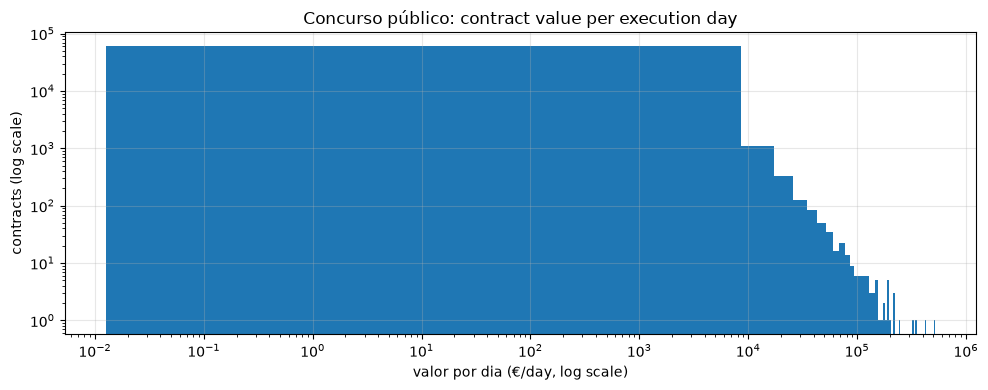

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = proc
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Concurso público: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    proc.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",5742,26362.0,1321.24,4.41522435e8
"""91-365 d""",30920,48676.375,191.39,6.6536e9
"""31-90 d""",9160,50945.0,803.15,1.2370e9
"""366-3650 d""",16743,77650.0,87.23,9.0338e9


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(proc, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))

shape: (2, 2)
┌───────────────────────┬───────┐
│ adjudicatarios_status ┆ count │
│ ---                   ┆ ---   │
│ str                   ┆ u32   │
╞═══════════════════════╪═══════╡
│ YES                   ┆ 61794 │
│ NO_NIF                ┆ 2182  │
└───────────────────────┴───────┘
shape: (2, 2)
┌───────────────────────────┬───────┐
│ adjudicatarios_key_source ┆ count │
│ ---                       ┆ ---   │
│ str                       ┆ u32   │
╞═══════════════════════════╪═══════╡
│ nipc                      ┆ 61794 │
│ name                      ┆ 2182  │
└───────────────────────────┴───────┘


In [9]:
by_adjudicante = (
    proc.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(proc, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Concurso público count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Concurso público value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))

Top 20 adjudicantes by Concurso público count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""508080142""",2177,1.8575e8,"""Unidade Local de Saúde de São …"
"""508481287""",1447,1.1476e8,"""Unidade Local de Saúde de Sant…"
"""500745471""",1357,1.2777e8,"""Santa Casa da Misericórdia de …"
"""510745997""",1293,8.1629e7,"""Unidade Local de Saúde do Alga…"
"""516726862""",889,3.3068e7,"""Unidade Local de Saúde de Lour…"
"""508080827""",804,6.9925e7,"""Unidade Local de Saúde do Alto…"
"""507618319""",788,9.6780e7,"""Unidade Local de Saúde de Lisb…"
"""600012662""",732,7.4525e7,"""Ministério da Defesa Nacional …"
"""509822932""",704,6.8322e7,"""Unidade Local de Saúde da Regi…"



Top 20 adjudicantes by Concurso público value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",519,2.7453e9,"""Infraestruturas de Portugal, S…"
"""600010686""",483,3.5359e8,"""Estado Maior da Força Aérea"""
"""512012032""",48,2.5809e8,"""EDA - Electricidade dos Açores…"
"""513606084""",268,2.1374e8,"""Águas do Norte, S. A."""
"""509540716""",385,1.8627e8,"""SPMS - Serviços Partilhados do…"
"""508080142""",2177,1.8575e8,"""Unidade Local de Saúde de São …"
"""511010435""",23,1.8282e8,"""EEM - Empresa de Electricidade…"
"""514387130""",187,1.7528e8,"""Águas do Tejo Atlântico, S. A."""
"""500051070""",246,1.6419e8,"""Município de Lisboa"""


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(proc.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")

Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""504223933""",573,9.1798e7,"""nipc""","""Medtronic Portugal, Lda."""
"""501506543""",525,2.0160e7,"""nipc""","""B BRAUN MEDICAL UNIPESSOAL, LD…"
"""504615947""",509,1.8788e8,"""nipc""","""MEO - Serviços de Comunicações…"
"""503531588""",393,7.4521e7,"""nipc""","""Lusopalex - Produtos de Saude …"
"""510533515""",345,5.8766e6,"""nipc""","""Medline Internacional Portugal…"
"""500271518""",339,3.5889e7,"""nipc""","""Sogenave - Sociedade Geral de …"
"""503281115""",301,8.6285e6,"""nipc""","""Clinifar,SA"""
"""500153370""",297,5.0081e7,"""nipc""","""JOHNSON &amp; JOHNSON LDA."""
"""504988964""",291,2.9538e7,"""nipc""","""Boston Scientific Portugal, Di…"



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""518400581""",1,1.6614e9,"""nipc""","""AVAN Norte – Gestão da Ferrovi…"
"""501489126""",46,3.6966e8,"""nipc""","""Domingos da Silva teixeira, S.…"
"""501323325""",87,2.2757e8,"""nipc""","""Uniself - Sociedade de Restaur…"
"""502124083""",101,2.1414e8,"""nipc""","""Iberdrola Clientes Portugal Un…"
"""500553408""",27,2.1044e8,"""nipc""","""Alexandre Barbosa Borges, S.A."""
"""504615947""",509,1.8788e8,"""nipc""","""MEO - Serviços de Comunicações…"
"""500197814""",21,1.7240e8,"""nipc""","""MOTA-ENGIL, ENGENHARIA E CONST…"
"""512033838""",2,1.6889e8,"""nipc""","""Bencom- Armazenamento e Comérc…"
"""500302200""",1,1.6696e8,"""nipc""","""ZAGOPE- Construções e Engenhar…"


awardee entries keyed by name fallback: 2,182 of 63,976 (3.4%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = proc.group_by("adjudicante_key", "adjudicante_name").len()
new = proc.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    proc.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)

adjudicante rows: 3,046 (key, name spelling) -> 2,009 keys
adjudicatario rows: 16,914 (key, name) -> 9,330 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""501413197""",30,260
"""501442600""",28,211
"""500792887""",23,69
"""600012662""",12,732
"""501559094""",10,128


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 63107.0       │
│ null_count ┆ 0.0           │
│ mean       ┆ 307651.127113 │
│ std        ┆ 6.8647e6      │
│ min        ┆ -111732.16    │
│ 25%        ┆ 11943.84      │
│ 50%        ┆ 51975.0       │
│ 75%        ┆ 167697.0      │
│ max        ┆ 1.6614e9      │
└────────────┴───────────────┘


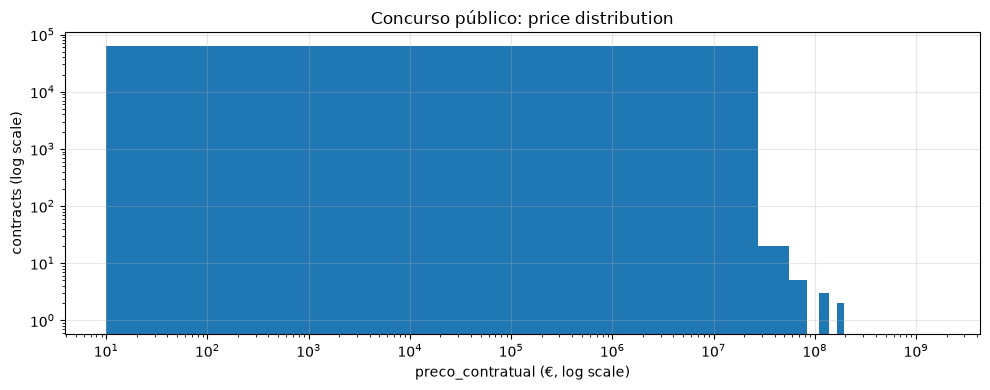

contracts above €5,000: 53,241
contracts above €20,000: 42,454
contracts above €75,000: 26,517


In [12]:
prices = proc["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Concurso público: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")

concorrentes reported: 61.7%


shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 38929.0  │
│ null_count ┆ 0.0      │
│ mean       ┆ 6.121375 │
│ std        ┆ 5.567892 │
│ min        ┆ 1.0      │
│ 25%        ┆ 2.0      │
│ 50%        ┆ 4.0      │
│ 75%        ┆ 8.0      │
│ max        ┆ 52.0     │
└────────────┴──────────┘


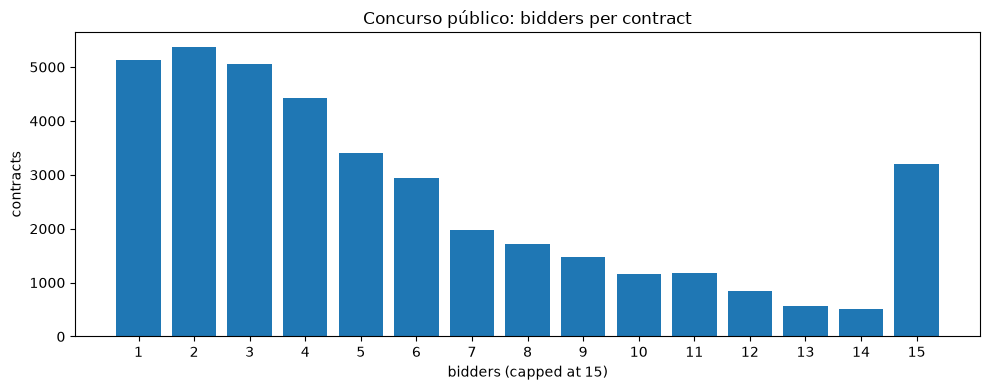

Single-bidder share among reported: 13.2%


TipoCriterioAdjudicacao,count
str,u32
"""Monofator""",45375
"""Multifator""",17149
null,580
"""Preço ou custo""",2
"""Melhor relação qualidade – pre…",1


In [13]:
# Competition: `concorrentes` is a "\n"-separated list of "NIPC-name" bidders (null = not reported).
proc = proc.with_columns(
    pl.col("concorrentes").str.split("\n").list.eval(pl.element().str.strip_chars().filter(pl.element() != "")).list.len().alias("n_concorrentes")
)
print(f"concorrentes reported: {proc['concorrentes'].is_not_null().mean():.1%}")
print(proc["n_concorrentes"].drop_nulls().describe())
fig, ax = plt.subplots()
counts = proc["n_concorrentes"].drop_nulls().clip(upper_bound=15).value_counts().sort("n_concorrentes")
ax.bar(counts["n_concorrentes"].cast(pl.String), counts["count"])
ax.set_xlabel("bidders (capped at 15)")
ax.set_ylabel("contracts")
ax.set_title("Concurso público: bidders per contract")
plt.tight_layout()
plt.show()
print("Single-bidder share among reported:", f"{(proc['n_concorrentes'] == 1).sum() / proc['n_concorrentes'].drop_nulls().len():.1%}")
display(proc["TipoCriterioAdjudicacao"].value_counts(sort=True))

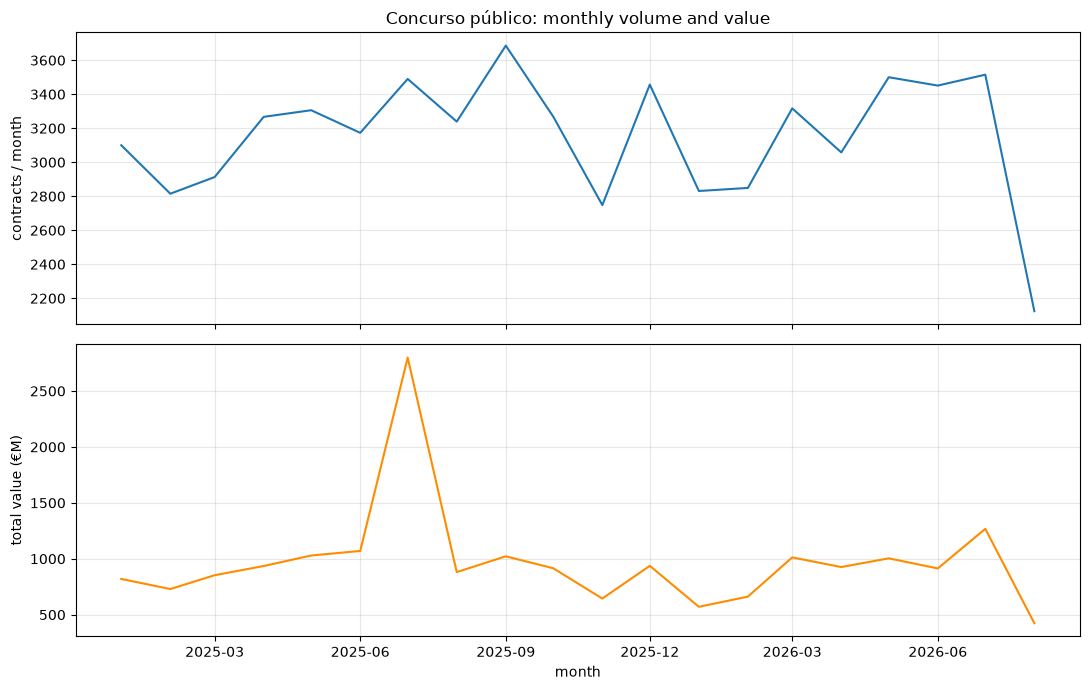

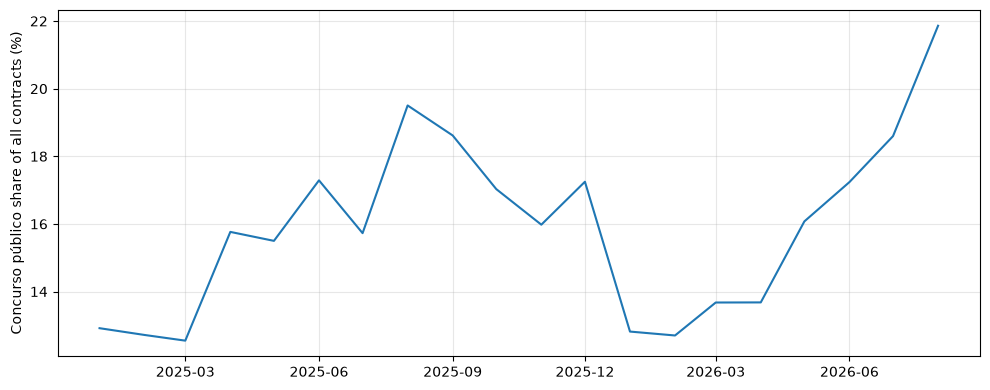

In [14]:
concurso_publico_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        CP_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(CP_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = concurso_publico_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Concurso público: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(concurso_publico_monthly["month"], concurso_publico_monthly["share"] * 100)
ax.set_ylabel("Concurso público share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
proc.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)

idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
11724697,"""Infraestruturas de Portugal, S…",1.6614e9,"""Concurso público""",2025-07-29,"""Concurso Público com Publicida…"
15377619,"""EDA - Electricidade dos Açores…",1.6833e8,"""Concurso público""",2026-07-27,"""Fornecimento de Fuelóleo para …"
15277559,"""Infraestruturas de Portugal, S…",1.6696e8,"""Concurso público""",2026-07-09,"""Empreitada LINHA DO ALENTEJO M…"
14944633,"""EEM - Empresa de Electricidade…",1.37543616e8,"""Concurso público""",2026-05-21,"""Fornecimento de gás natural pa…"
12066272,"""IP - Infraestruturas de Portug…",1.1981e8,"""Concurso público""",2025-12-11,"""L. VENDAS NOVAS-MODERNIZAÇÃO"""
14906514,"""Infraestruturas de Portugal, S…",1.135e8,"""Concurso público""",2026-05-05,"""Empreitada L. MINHO - CONTUMIL…"
11456600,"""Instituto Nacional de Emergênc…",7.747516e7,"""Concurso público""",2025-05-20,"""1140/2024 - locação de meios a…"
15253476,"""Infraestruturas de Portugal""",7.5996e7,"""Concurso público""",2026-06-23,"""Empreitada L. NORTE - OVAR (VÁ…"
14474225,"""Infraestruturas de Portugal, S…",7.02e7,"""Concurso público""",2026-03-30,"""Empreitada EN222 - A32/IC2 (NÓ…"


## Commentary and limitations

- `Ano` covers 2025–2026 only; edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`) and may over- or under-merge; see `key_source`. Dirty NIPCs stay separate keys.
- Very large values may be outliers or data-entry errors.
- `concorrentes` is missing for many contracts; bidder statistics use reported values only.
- Contracts with |value| below €10 (`MIN_VALUE`, applied to the absolute value) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.